In [2]:
#import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV

In [16]:
#load dataset
url = 'https://raw.githubusercontent.com/pkmklong/Breast-Cancer-Wisconsin-Diagnostic-DataSet/master/data.csv'
df = pd.read_csv(url)

In [17]:
#looking first 5 row to the dataset
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [18]:
#looking last 5 row of the dataset
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.00466,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [19]:
#how many row and the columns in the dataset
df.shape

(569, 33)

In [20]:
#removing unused columns
df.drop('id', axis=1, inplace=True)

In [21]:
df.drop('Unnamed: 32', axis=1, inplace=True)

The ID and unknown columns were removed. ID was dropped to prevent overfitting by avoiding identity memorization, while the unknown column had no useful information.

In [22]:
#information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [23]:
#Handling Missing Values
#checking for missing values
df.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


In [24]:
#Exploratory Data Analysis
#describing the dataset
df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


/tmp/ipykernel_1546/827447546.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plot       = sns.barplot(x = label_plot, y = data_plot, palette = 'CMRmap')


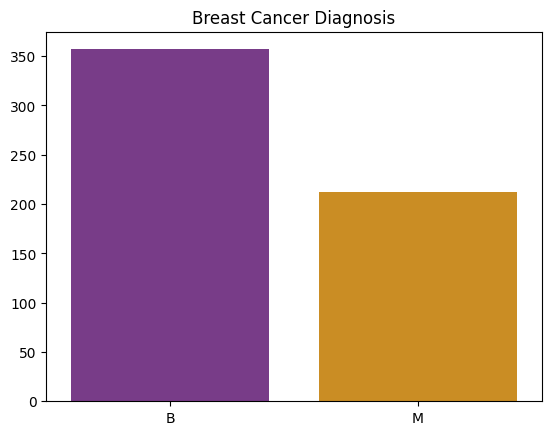

In [25]:
#univariate analysis diagnosis
data_plot  = df['diagnosis'].value_counts().to_list()
label_plot = df['diagnosis'].value_counts().index.to_list()

title = 'Breast Cancer Diagnosis'

plot       = sns.barplot(x = label_plot, y = data_plot, palette = 'CMRmap')
plot_title = plt.title(title)

plt.show()

In [26]:
df['diagnosis'].value_counts()

,count
diagnosis,
B,357
M,212


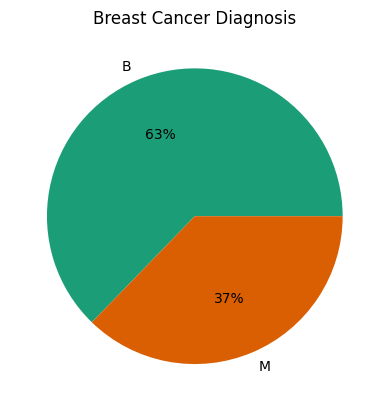

In [30]:
color = sns.color_palette('Dark2')
plot = plt.pie(data_plot, labels=label_plot, colors=color, autopct='%0.f%%')
plot_title=plt.title(title)
plt.show()

The diagnosis distribution shows 357 benign (63%) and 212 malignant (37%) cases, indicating that most patients in the dataset had a benign diagnosis.

/tmp/ipykernel_1546/3380659722.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=var, data=df, palette = 'colorblind', ax=axs[i])
/tmp/ipykernel_1546/3380659722.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=var, data=df, palette = 'colorblind', ax=axs[i])
/tmp/ipykernel_1546/3380659722.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=var, data=df, palette = 'colorblind', ax=axs[i])
/tmp/ipykernel_1546/3380659722.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0.

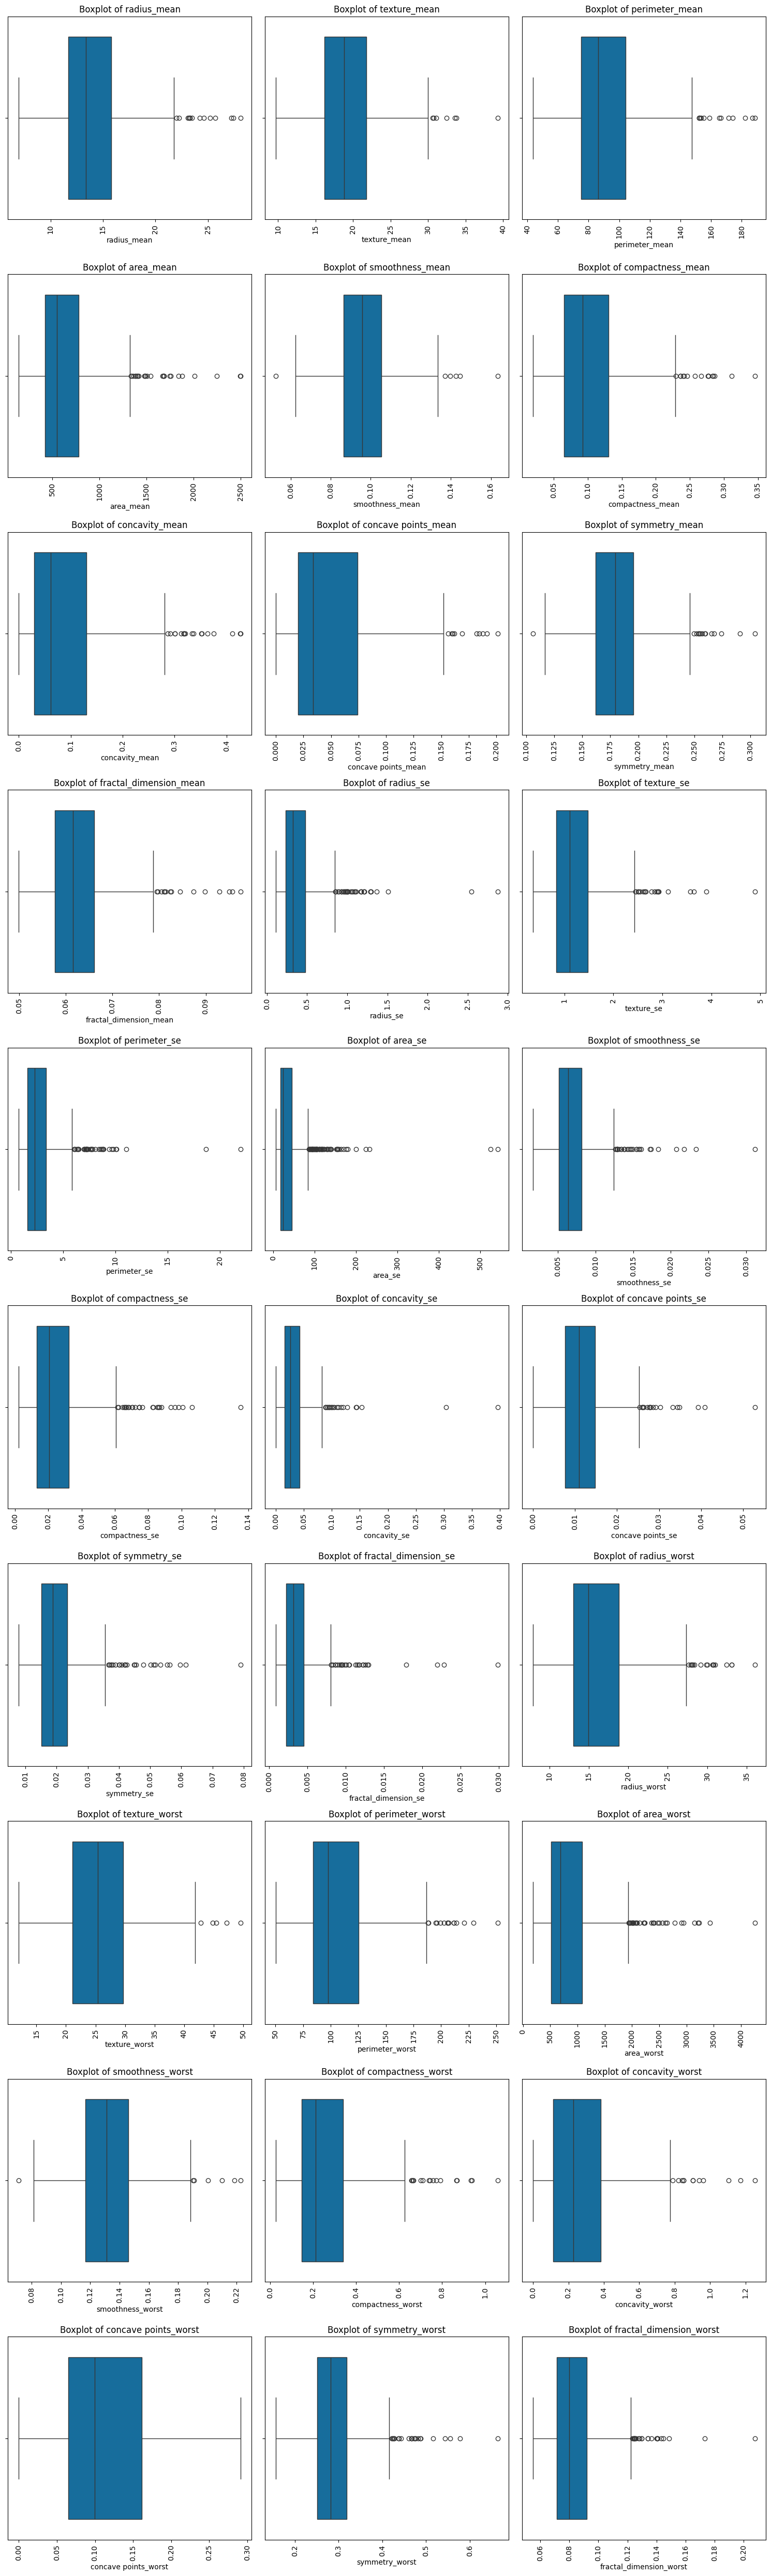

In [34]:

#Boxplot of numeric variables
column_name_list_num = ['radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst']

#Create subplots
num_cols = len(column_name_list_num)
num_rows = (num_cols + 2) // 3
fig, axs = plt.subplots(nrows=num_rows, ncols=3, figsize=(15,5*num_rows))
axs = axs.flatten()

#Boxplot for each variables
for i, var in enumerate (column_name_list_num):
  sns.boxplot(x=var, data=df, palette = 'colorblind', ax=axs[i])
  axs[i].set_title("Boxplot of" + " " + var)
  axs[i].tick_params(axis='x', rotation=90)

#Removes extra empty subplots
if num_cols < len(axs):
  for i in range(num_cols, len(axs)):
    fig.delaxes(axs[i])

fig.tight_layout()
plt.show()

Box plots visualize the distribution and spread of numerical features, showing quartiles, the interquartile range (IQR), minimum and maximum values, and potential outliers.

/tmp/ipykernel_1546/2270142318.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=var, data=df, palette = 'rocket', ax=axs[i])
/tmp/ipykernel_1546/2270142318.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=var, data=df, palette = 'rocket', ax=axs[i])
/tmp/ipykernel_1546/2270142318.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=var, data=df, palette = 'rocket', ax=axs[i])
/tmp/ipykernel_1546/2270142318.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign

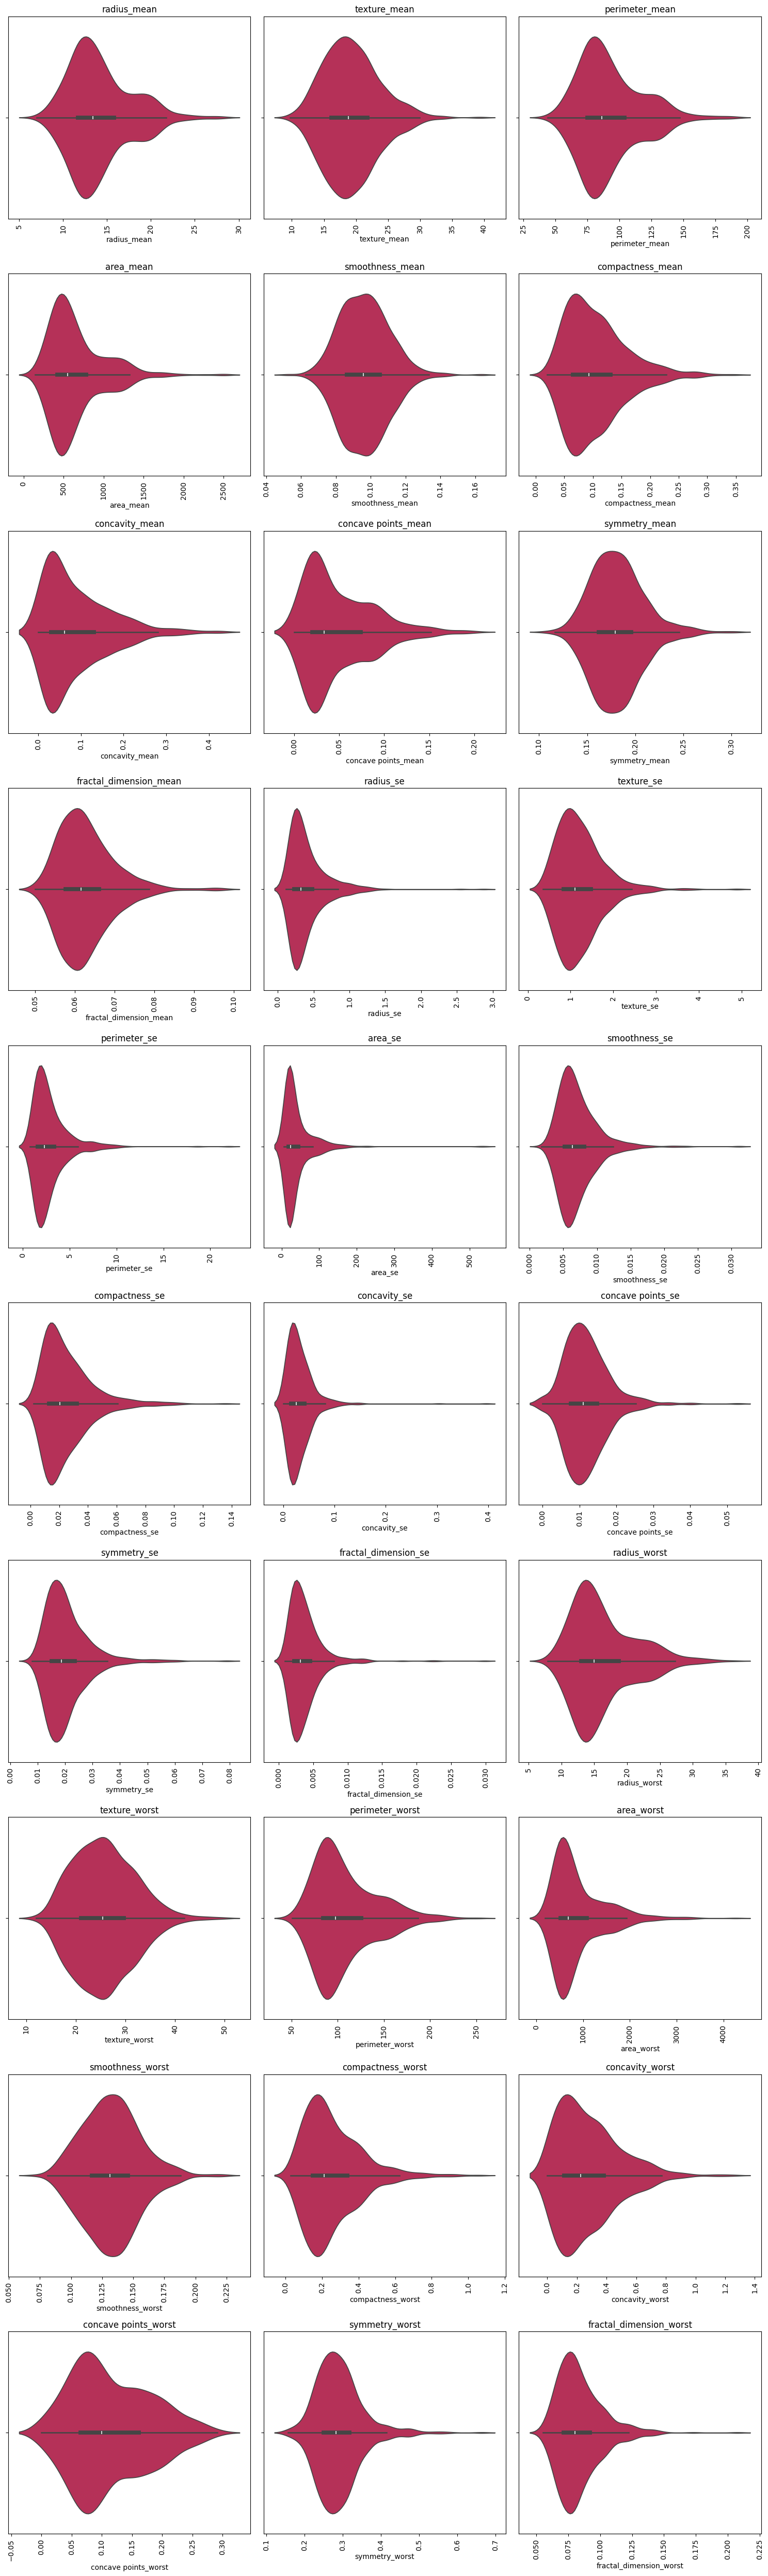

In [36]:
#Create subplots
num_cols = len(column_name_list_num)
num_rows = (num_cols + 2) // 3
fig, axs = plt.subplots(nrows=num_rows, ncols=3, figsize=(15,5*num_rows))
axs = axs.flatten()

#Violin plot for each variables
for i, var in enumerate (column_name_list_num):
  sns.violinplot(x=var, data=df, palette = 'rocket', ax=axs[i])
  axs[i].set_title(var)
  axs[i].tick_params(axis='x', rotation=90)

#Removes extra empty subplots
if num_cols < len(axs):
  for i in range(num_cols, len(axs)):
    fig.delaxes(axs[i])

fig.tight_layout()
plt.show()

Violin plot is a variation of box plot plus kernel density plot. A violin plot is created for each numerical column.

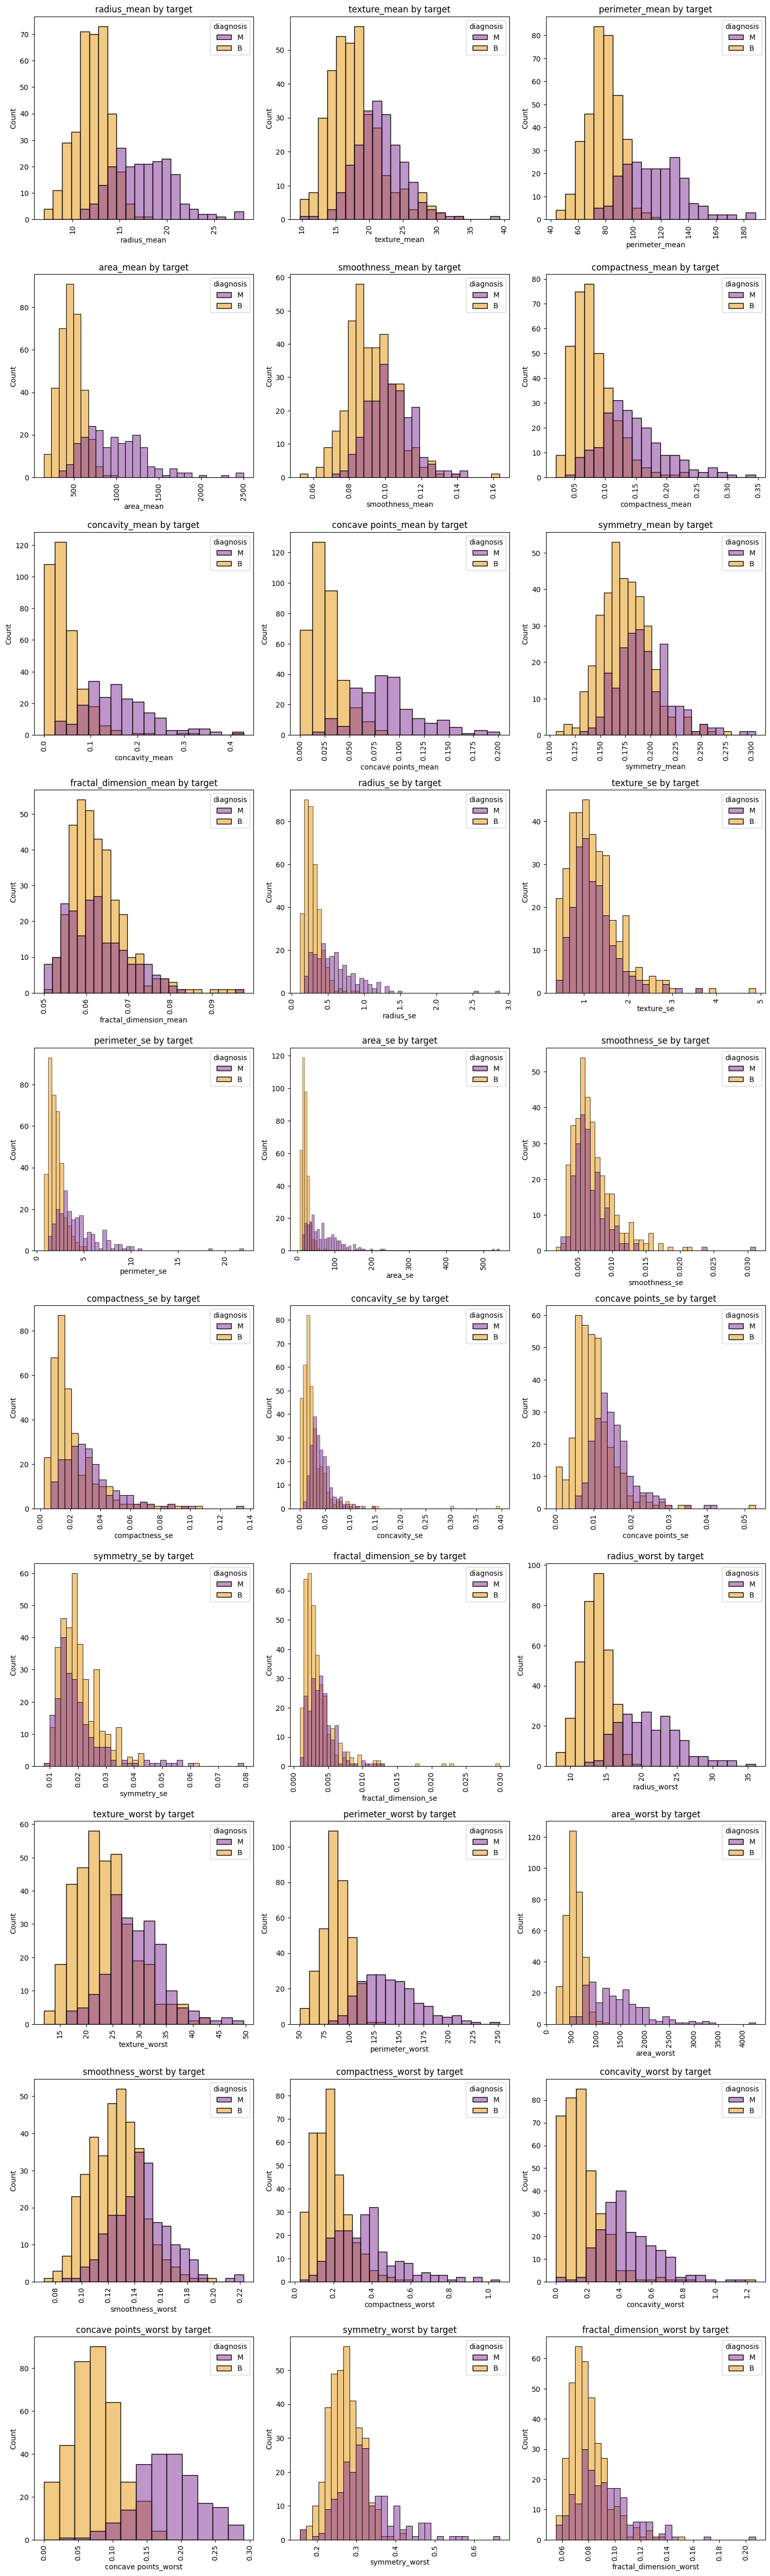

In [37]:
#Histogram overlay of 'diagnosis' with the independent variables
#Create subplots
num_cols = len(column_name_list_num)
num_rows = (num_cols + 2) // 3
fig, axs = plt.subplots(nrows=num_rows, ncols=3, figsize=(15,5*num_rows))
axs = axs.flatten()

#Histplot for each variables
for i, var in enumerate (column_name_list_num):
  sns.histplot(x=var, hue = 'diagnosis', data=df, palette = 'CMRmap', ax=axs[i])
  axs[i].set_title(var + " " + "by target")
  axs[i].tick_params(axis='x', rotation=90)

#Removes extra empty subplots
if num_cols < len(axs):
  for i in range(num_cols, len(axs)):
    fig.delaxes(axs[i])

fig.tight_layout()
plt.show()

Histograms show the distribution of numerical features by diagnosis. The plots indicate that patients with benign tumors generally have smaller tumor measurements than those with malignant tumors.

/tmp/ipykernel_1546/816634748.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(y=var, x='diagnosis', data=df, palette = 'CMRmap', ax=axs[i])
/tmp/ipykernel_1546/816634748.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(y=var, x='diagnosis', data=df, palette = 'CMRmap', ax=axs[i])
/tmp/ipykernel_1546/816634748.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(y=var, x='diagnosis', data=df, palette = 'CMRmap', ax=axs[i])
/tmp/ipykernel_1546/816634748.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecat

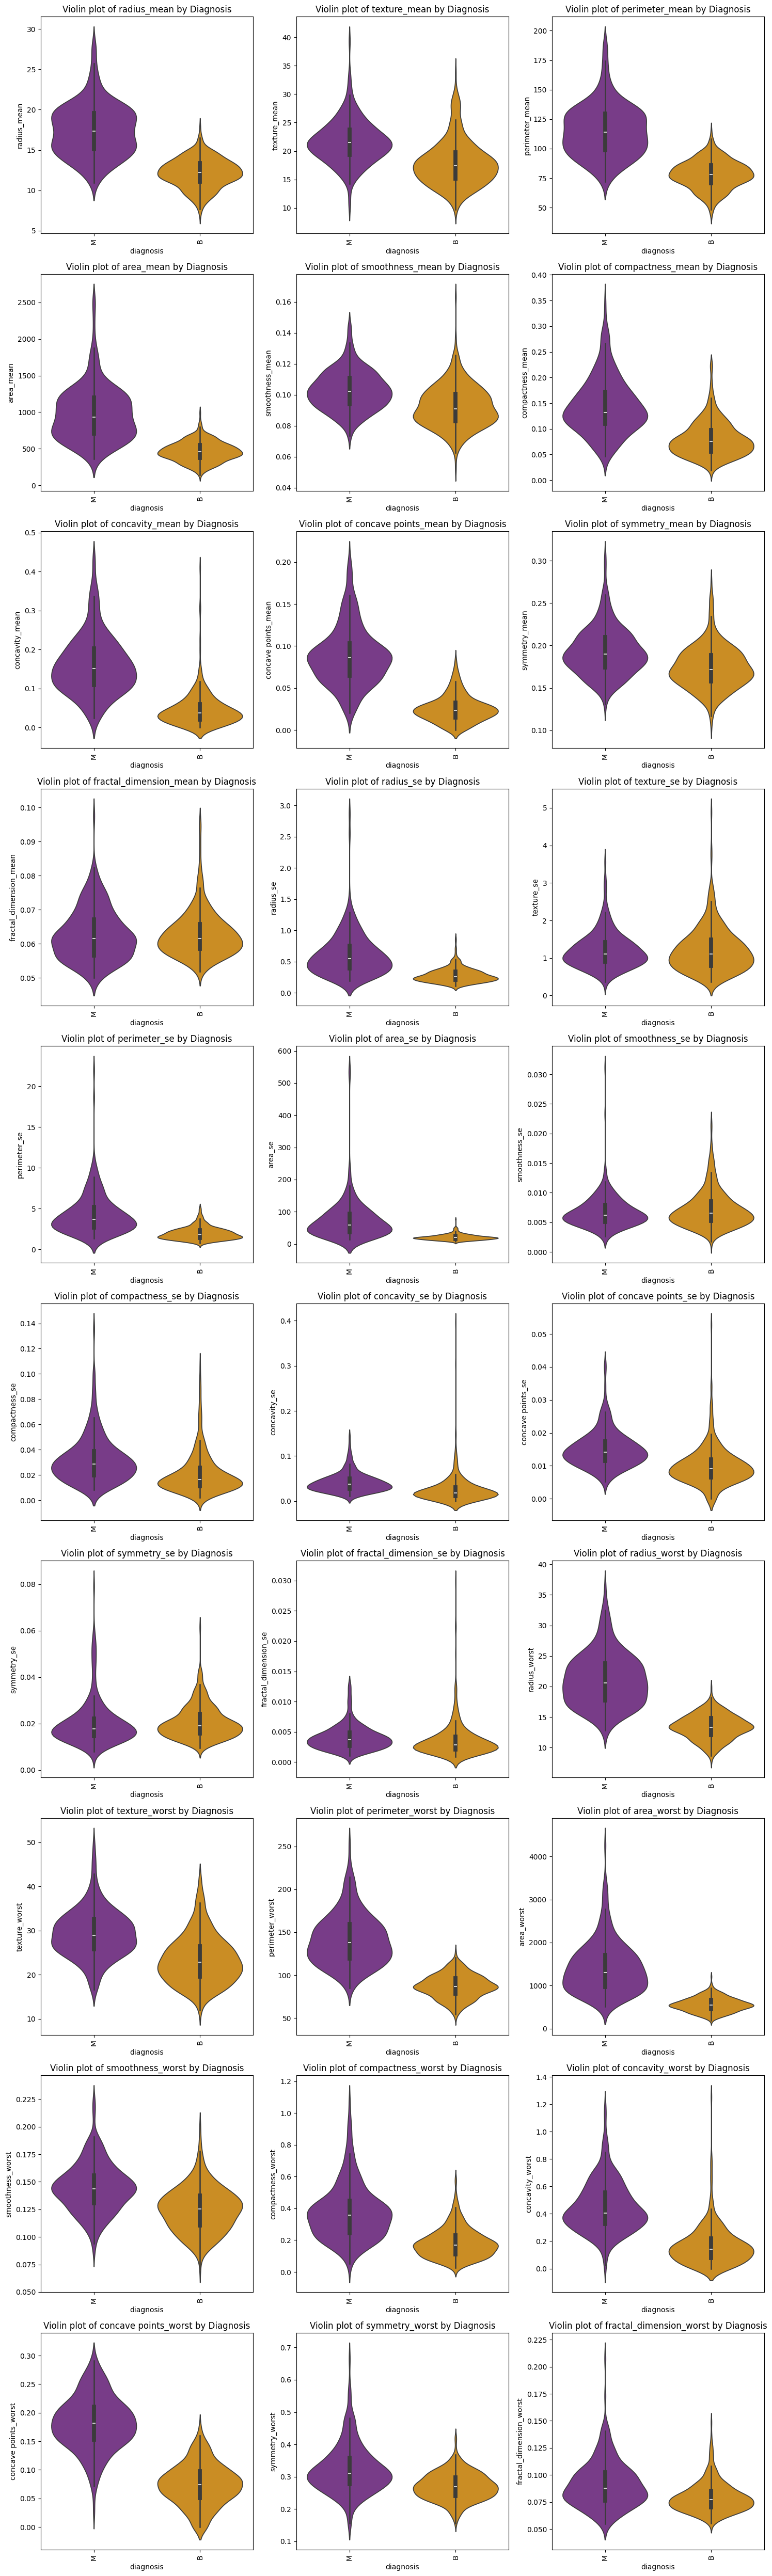

In [38]:

#Create subplots
num_cols = len(column_name_list_num)
num_rows = (num_cols + 2) // 3
fig, axs = plt.subplots(nrows=num_rows, ncols=3, figsize=(15,5*num_rows))
axs = axs.flatten()

#Violin plot for each variables
for i, var in enumerate (column_name_list_num):
  sns.violinplot(y=var, x='diagnosis', data=df, palette = 'CMRmap', ax=axs[i])
  axs[i].set_title("Violin plot of" + " " + var + " " + "by Diagnosis")
  axs[i].tick_params(axis='x', rotation=90)

#Removes extra empty subplots
if num_cols < len(axs):
  for i in range(num_cols, len(axs)):
    fig.delaxes(axs[i])

fig.tight_layout()
plt.show()

Violin plots visualize the distribution of numerical features across benign and malignant diagnoses, highlighting differences in their data distributions.

In [39]:
#mean of each column values in each class
df.groupby(by='diagnosis').mean()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
diagnosis,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
B,12.146524,17.914762,78.075406,462.790196,0.092478,0.080085,0.046058,0.025717,0.174186,0.062867,0.284082,1.220380,2.000321,21.135148,0.007196,0.021438,0.025997,0.009858,0.020584,0.003636,13.379801,23.515070,87.005938,558.899440,0.124959,0.182673,0.166238,0.074444,0.270246,0.079442
M,17.462830,21.604906,115.365377,978.376415,0.102898,0.145188,0.160775,0.087990,0.192909,0.062680,0.609083,1.210915,4.323929,72.672406,0.006780,0.032281,0.041824,0.015060,0.020472,0.004062,21.134811,29.318208,141.370330,1422.286321,0.144845,0.374824,0.450606,0.182237,0.323468,0.091530


In [40]:
#labelling categorical data
diagnosis={
    'B':0,
    'M':1,
}
df['diagnosis']=df['diagnosis'].map(diagnosis)

The categorical diagnosis column was converted into numeric values using a dictionary mapping: B (Benign) = 0 and M (Malignant) = 1 for model training.

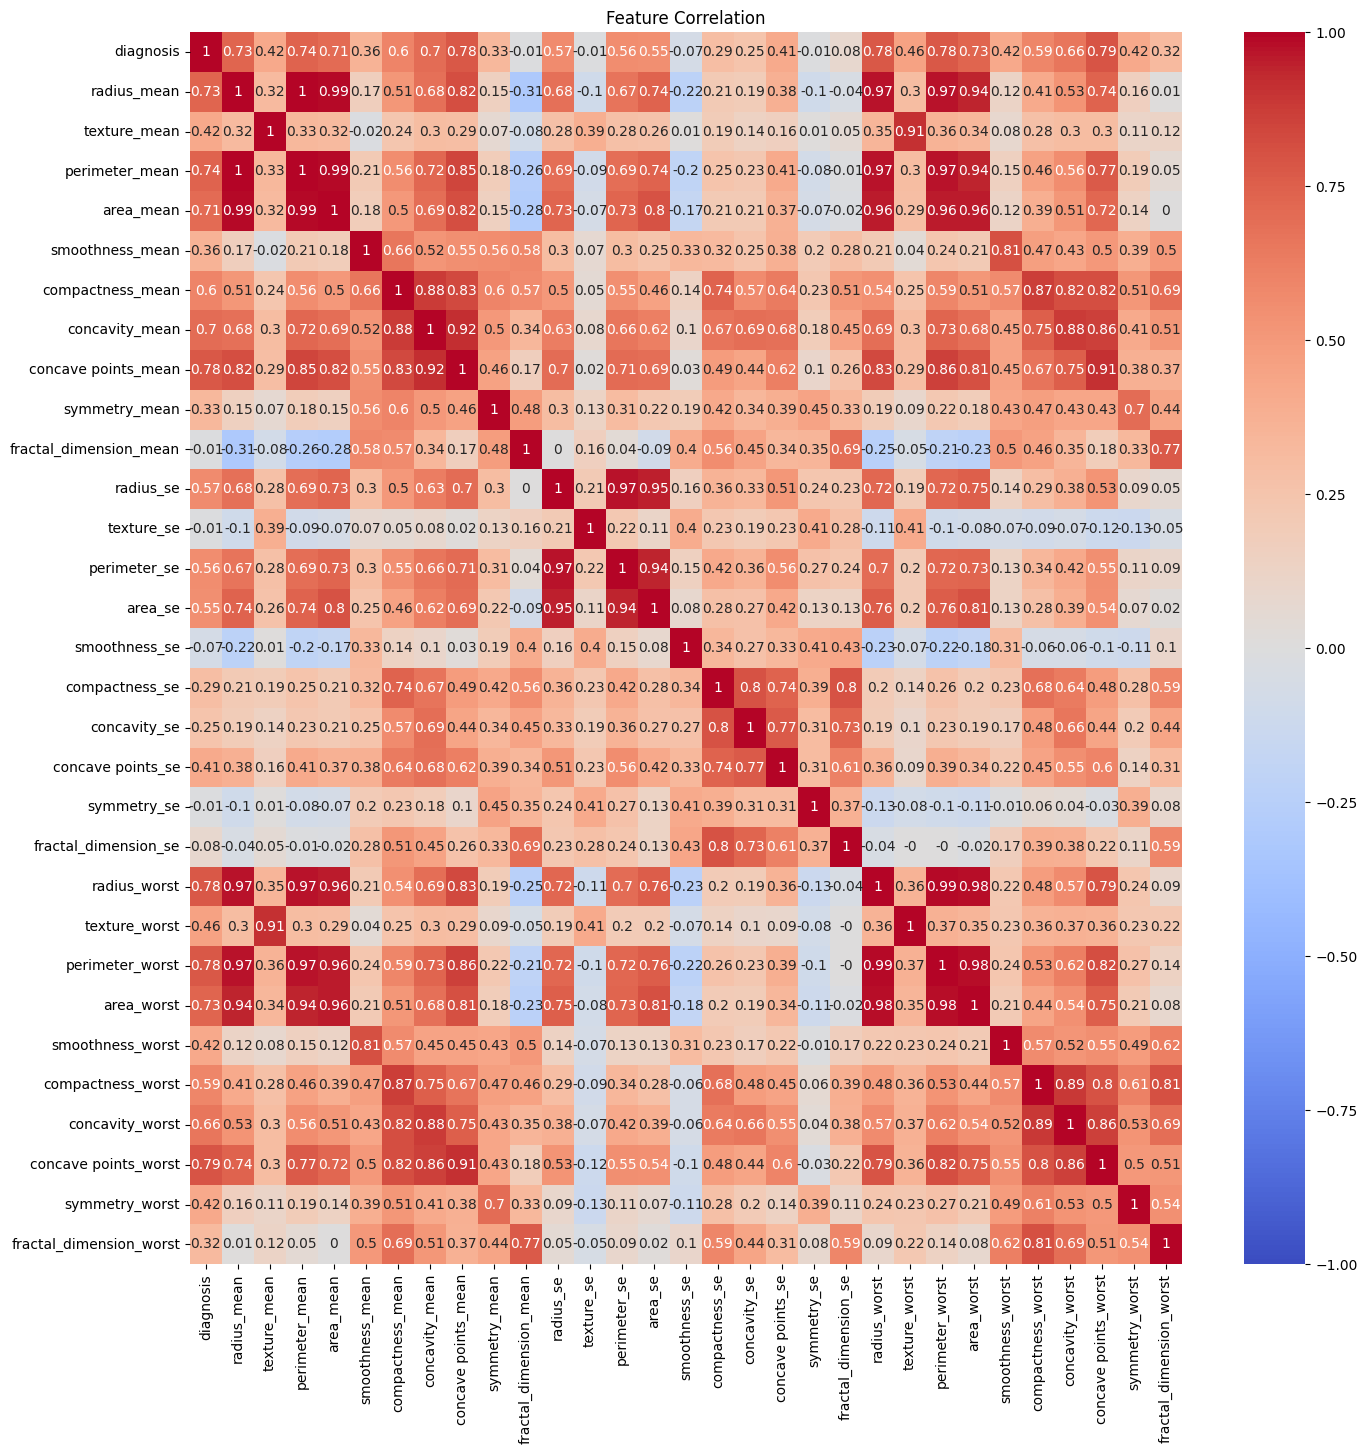

In [41]:
#correlations between features
matrix = df.corr().round(2)
plt.figure(figsize=(16,16))
sns.heatmap(matrix, annot=True, vmax=1, vmin=-1, center=0, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

The correlation heatmap shows relationships between numerical features, with values rounded to two decimal places. Positive correlation indicates features increase together, while negative correlation means one tends to decrease as the other increases. Higher absolute values indicate stronger correlations.

In [42]:
#The dataset was balanced to address class imbalance, then split into training and testing sets to train the model and evaluate its performance on unseen data.

In [43]:
#defining x and y
x=df.drop(columns=['diagnosis'])
y=df['diagnosis']

The dataset is split into train and test with a ratio of 80:20. The reason why this number is set is because 80/20 is generally considered good enough (unless the training data is very large, then the split data ratio may change).

In [44]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

SMOTE was used to balance the dataset by generating synthetic samples for the minority class, helping the model learn both classes more effectively.

In [45]:
from imblearn.over_sampling import SMOTE
SMOTE=SMOTE()
#fit and apply the transform
x_train, y_train=SMOTE.fit_resample(x_train, y_train)

In [49]:
x_train.shape, x_test.shape

((572, 30), (114, 30))

In [50]:
#modeling
#gradient boosting
from sklearn.ensemble import GradientBoostingClassifier
gb=GradientBoostingClassifier()

In [51]:
#training the model
gb.fit(x_train, y_train)

GradientBoostingClassifier()

In [55]:
#predict testing set
y_pred_gb=gb.predict(x_test)

In [56]:
print('Training-set accuracy score:', gb.score(x_train, y_train))
print('Test-set accuracy score:', gb.score(x_test, y_test))

Training-set accuracy score: 1.0
Test-set accuracy score: 0.9473684210526315


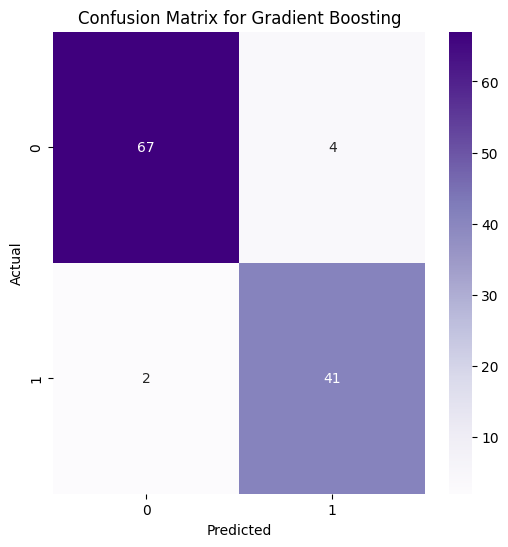

In [58]:
plt.figure(figsize=(6,6))
sns.heatmap(confusion_matrix(y_test,y_pred_gb), annot=True, fmt='d', cmap='Purples')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Gradient Boosting')
plt.show()

In [60]:
#Check model performance using classification_report
print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           0       0.97      0.94      0.96        71
           1       0.91      0.95      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



In [61]:
#Specificity
cm = confusion_matrix(y_test, y_pred_gb)

specificity = cm[1,1]/(cm[1,0] + cm[1,1])
print('Specificity : ', specificity)

Specificity :  0.9534883720930233


In [63]:
#Check model performance using auc score
roc_auc_score(y_test, y_pred_gb)*100

np.float64(94.85751719620045)

In [65]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

classifier_rf=RandomForestClassifier()
classifier_rf.fit(x_train,y_train)

y_pred_rf=classifier_rf.predict(x_test)

In [66]:
print('Training-set accuracy score:', classifier_rf.score(x_train, y_train))
print('Test-set accuracy score:', classifier_rf.score(x_test, y_test))

Training-set accuracy score: 1.0
Test-set accuracy score: 0.9824561403508771


In [67]:
#Classification report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99        71
           1       0.98      0.98      0.98        43

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [68]:
#Specificity
cm = confusion_matrix(y_test, y_pred_rf)

specificity = cm[1,1]/(cm[1,0] + cm[1,1])
print('Specificity : ', specificity)

Specificity :  0.9767441860465116


In [69]:
roc_auc_score(y_test, y_pred_rf)*100

np.float64(98.1329839502129)

In [72]:
#stacking model

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier

In [73]:
base_models = [('Decision Tree',DecisionTreeClassifier()),('Logistic Regression',LogisticRegression()), ('Random Forest', RandomForestClassifier()), ('xgb', XGBClassifier())]
stacking = StackingClassifier(estimators = base_models, final_estimator = LogisticRegression(), cv = 5)
stacking.fit(x_train , y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

StackingClassifier(cv=5,
                   estimators=[('Decision Tree', DecisionTreeClassifier()),
                               ('Logistic Regression', LogisticRegression()),
                               ('Random Forest', RandomForestClassifier()),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categori...
                                              importance_type=None,
                                              interaction_constraints=None,
                                              learning_rate=None, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None,
                                              max_depth=None, max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=None, n_jobs=None,
                                              num_parallel_tree=None, ...))],
                   final_estimator=LogisticRegression())

In [77]:
y_pred_st = stacking.predict(x_test)

In [78]:
print('Training-set accuracy score:', stacking.score(x_train, y_train))
print('Test-set accuracy score:', stacking.score(x_test, y_test))

Training-set accuracy score: 1.0
Test-set accuracy score: 0.9824561403508771


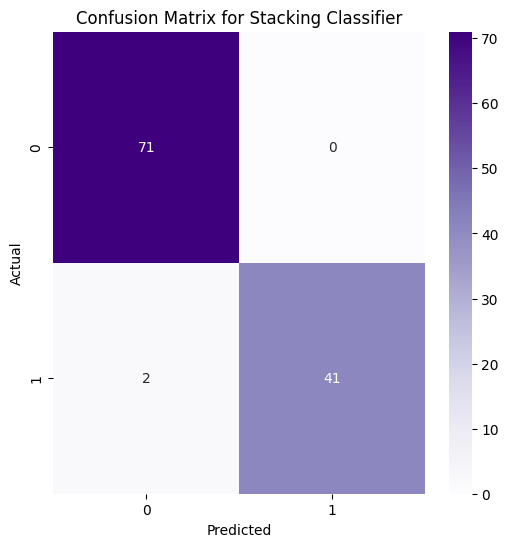

In [79]:
plt.figure(figsize=(6,6))
sns.heatmap(confusion_matrix(y_test,y_pred_st), annot=True, fmt='d', cmap='Purples')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Stacking Classifier')
plt.show()

In [80]:
#Classification report
print(classification_report(y_test, y_pred_st))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [82]:
#Specificity
cm = confusion_matrix(y_test, y_pred_st)

specificity = cm[1,1]/(cm[1,0] + cm[1,1])
print('Specificity : ', specificity)

Specificity :  0.9534883720930233


In [83]:
roc_auc_score(y_test, y_pred_st)*100

np.float64(97.67441860465115)

Conclusion: Random Forest performed best overall, achieving the highest recall and specificity compared with Gradient Boosting and Stacking Classifier. These metrics are important in breast cancer diagnosis for identifying malignant cases and reducing false positives.